In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

In [2]:
df = pd.read_csv(r"D:\1_Python Programmes\Projects\HDD\data\heart_disease_cleaned.csv")

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

numerical_features = [
    "age", "trestbps", "chol",
    "thalch", "oldpeak", "ca"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "thal"
]

numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    ))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

In [4]:
X = df.drop(columns = ["id","dataset","num"])
y = df["num"]

for col in categorical_features:
    X[col] = X[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

# Same train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

svm_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=42
    ))
])

In [5]:
svm_pipeline.fit(X_train, y_train)

print("SVM training completed!")

SVM training completed!


In [6]:
# Predictions
y_pred_svm = svm_pipeline.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Compare actual and predicted values
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_svm
})

display(results.head(15))

print("Accuracy:", accuracy_score(y_test, y_pred_svm))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_svm))

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_svm))

,Actual,Predicted
0,1,0
1,1,1
2,1,1
3,1,1
4,0,1
5,0,1
6,0,1
7,1,1
8,0,1
9,1,0


Accuracy: 0.7119565217391305

Classification Report:

              precision    recall  f1-score   support

           0       0.72      0.59      0.64        82
           1       0.71      0.81      0.76       102

    accuracy                           0.71       184
   macro avg       0.71      0.70      0.70       184
weighted avg       0.71      0.71      0.71       184

Confusion Matrix:
 [[48 34]
 [19 83]]


SVM ROC-AUC: 0.7208273553323767


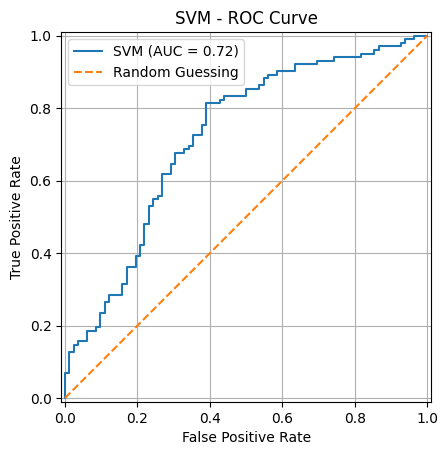

In [7]:
y_prob = svm_pipeline.predict_proba(X_test)[:, 1]

# ROC-AUC score
svm_roc_auc = roc_auc_score(y_test, y_prob)

print("SVM ROC-AUC:", svm_roc_auc)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="SVM"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guessing")

plt.title("SVM - ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.grid(True)
plt.legend()
plt.show()

In [8]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "classifier__C": [0.1, 1, 10],
    "classifier__gamma": ["scale", 0.01],
    "classifier__kernel": ["rbf", "linear"]
}

# Disable probability estimation during tuning
svm_pipeline.set_params(classifier__probability=False)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV ROC-AUC:", grid_search.best_score_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters: {'classifier__C': 0.1, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}
Best CV ROC-AUC: 0.8966164318467842


In [9]:
best_svm = grid_search.best_estimator_

# Enable probability estimation
best_svm.set_params(classifier__probability=True)

# Train final model
best_svm.fit(X_train, y_train)

print("Best SVM model trained!")

Best SVM model trained!


In [10]:
y_pred_svm = best_svm.predict(X_test)
y_prob_svm = best_svm.predict_proba(X_test)[:, 1]

print("Test ROC-AUC:", roc_auc_score(y_test, y_prob_svm))
print("Accuracy:", accuracy_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

Test ROC-AUC: 0.9131994261119082
Accuracy: 0.8478260869565217

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.78      0.82        82
           1       0.84      0.90      0.87       102

    accuracy                           0.85       184
   macro avg       0.85      0.84      0.84       184
weighted avg       0.85      0.85      0.85       184



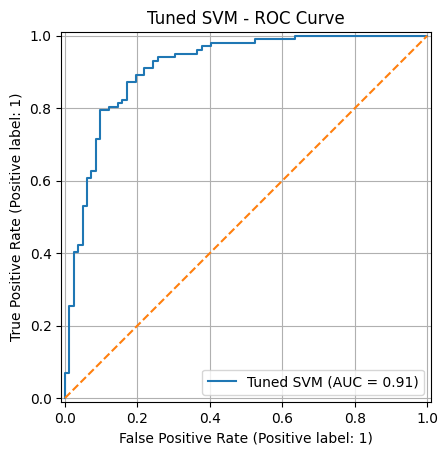

In [11]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob_svm,
    name="Tuned SVM"
)

plt.plot([0, 1], [0, 1], "--")
plt.title("Tuned SVM - ROC Curve")
plt.grid(True)
plt.show()

In [13]:
import joblib
# joblib.dump(best_svm,"D:/1_Python Programmes/Projects/HDD/models/svm_model.pkl")


# print("Tuned SVM saved successfully!")

Tuned SVM saved successfully!


In [15]:
lr_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/logistic_r_model.pkl")
knn_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/heart_disease_knn.pkl")
decision_tree_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/decision_tree_model.pkl")
rf_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/random_forest_model.pkl")
svm_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/svm_model.pkl")

models = {
    "Logistic Regression": lr_model,
    "KNN": knn_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": rf_model,
    "SVM" : svm_model
}

comparison = {}

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    comparison[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "Specificity": tn / (tn + fp),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

comparison_df = pd.DataFrame(comparison).T.round(4)

display(comparison_df)

,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC
Logistic Regression,0.8533,0.8505,0.8922,0.8049,0.8708,0.9143
KNN,0.8478,0.8700,0.8529,0.8415,0.8614,0.9030
Decision Tree,0.7554,0.7568,0.8235,0.6707,0.7887,0.7471
Random Forest,0.8533,0.8505,0.8922,0.8049,0.8708,0.9228
SVM,0.8478,0.8364,0.9020,0.7805,0.8679,0.9132


In [20]:
comparison_df.to_csv(
    "D:/1_Python Programmes/Projects/HDD/reports/model_comparison.csv",
    index=True,
    index_label="Model"
)